# LocalClinical-Tuner - full pipeline walkthrough

This notebook walks through every stage of the project on the artifacts produced by
`bash scripts/run_full_pipeline.sh`:

1. Scenario sampling for synthetic notes
2. The dataset (70% synthetic / 30% public, splits, label provenance)
3. The quality filter (rule-based clinical checks + LLM critic)
4. The exact prompt format the model is trained and served with
5. Training (QLoRA SFT -> ORPO): curves and resources
6. Evaluation: base vs SFT vs SFT+ORPO (+ quantized GGUF)
7. Local inference through Ollama's OpenAI-compatible API

Everything runs locally. Cells only *read* pipeline outputs unless you set `RUN_HEAVY = True`.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from IPython.display import Markdown, display  # noqa: E402

from clinical_tuner.config import load_config  # noqa: E402
from clinical_tuner.utils import read_json, read_jsonl  # noqa: E402

RUN_HEAVY = False          # True: re-run tiny training stages from the notebook (needs a GPU)
cfg = load_config()
print("base model:", cfg.model.base_model, "| results dir:", cfg.project.results_dir)

base model: Qwen/Qwen2.5-7B-Instruct | results dir: results


## 1. Scenario sampling

Each synthetic note starts from a sampled scenario (specialty x presenting problem x note style x difficulty x
setting x demographics x complicating factors). The same seeded sampler drives the API path and the chat-app
batches, so scenario ids are identical across both.

In [2]:
import random

from clinical_tuner.taxonomy import DIFFICULTIES, NOTE_STYLES, all_problems, sample_scenario

rng = random.Random(cfg.project.seed)
rows = [sample_scenario(rng, f"syn-{i:05d}") for i in range(6)]
table = "| id | specialty | patient | problem | style | difficulty |\n|---|---|---|---|---|---|\n"
table += "\n".join(f"| {s.encounter_id} | {s.specialty} | {s.age}{s.sex} | {s.problem} | {s.style} | {s.difficulty} |"
                    for s in rows)
display(Markdown(table))
print(len(all_problems()), "presenting problems,", len(NOTE_STYLES), "note styles,", len(DIFFICULTIES), "difficulty levels")

| id | specialty | patient | problem | style | difficulty |
|---|---|---|---|---|---|
| syn-00000 | internal medicine (hospitalist) | 72M | sepsis from a urinary source | dictation | easy |
| syn-00001 | pediatrics | 0F | fever in a young infant | dialogue_transcript | medium |
| syn-00002 | family medicine | 23F | uncontrolled essential hypertension | dialogue_transcript | hard |
| syn-00003 | urology | 66M | erectile dysfunction | telehealth_note | hard |
| syn-00004 | infectious disease | 71F | recurrent Clostridioides difficile infection | terse_shorthand | medium |
| syn-00005 | obstetrics and gynecology | 48F | abnormal uterine bleeding | dialogue_transcript | easy |

164 presenting problems, 8 note styles, 3 difficulty levels


## 2. The dataset

Composition, split sizes, and one held-out test encounter with its three reference outputs.

In [3]:
split = read_json("data/processed/split_stats.json")
display(Markdown("| split | " + " | ".join(split["sources"]) + " |\n|---|" + "---|" * len(split["sources"]) + "\n" +
                 "\n".join(f"| {s} | " + " | ".join(str(split["by_split_source"].get(s, {}).get(src, 0))
                                                  for src in split["sources"]) + " |" for s in split["splits"])))
print(f"{split['total_encounters']} encounters -> {split['total_examples']} examples, "
      f"{split['achieved_synthetic_fraction']:.1%} synthetic; note writers: {split.get('generators')}")

| split | aci-bench | mts-dialog | synthetic |
|---|---|---|---|
| test | 4 | 26 | 70 |
| val | 1 | 6 | 18 |
| pref | 7 | 38 | 105 |
| train | 33 | 185 | 507 |

1000 encounters -> 3000 examples, 70.0% synthetic; note writers: {'claude-sonnet-5-5 (Claude Code subagent)': 700, 'dataset:mts-dialog': 255, 'dataset:aci-bench': 45}


In [4]:
test = read_jsonl("data/processed/test.jsonl")
ex = {r["task"]: r for r in test if r["encounter_id"] == test[0]["encounter_id"]}
print(ex["summary"]["note"][:1500], "...\n")
for task in ("summary", "soap", "entities"):
    print(f"--- reference: {task} ---\n{ex[task]['reference'][:900]}\n")

Doctor: so [NAME] is a 45 -year-old male who came in today with an ankle injury [NAME] what happened
Patient: hey doctor [NAME] yeah so my son [NAME] i think you met in the past he he started playing basketball and there we do multiple seasons and so we're kinda getting ready for the next season that starts in in april and we were at the courts plan and i went up for a shot and he's far more aggressive than with me than he is with you know his peers i guess he could say and so he he found me while i was going for a lap and then when i came down i kind of landed awkwardly and i kind of like rolled and twisted my my ankle so now it's it's hurting a bit like kind of on the outside you can you can even see it's it's bruised up and a bit swollen
Doctor: yeah
Patient: and yeah i've been having trouble walking and it just does n't feel solid really stable which is a problem i i recently got back into working out and i had been in a really good rhythm going to the gym
Doctor: okay
Patient: and

## 3. The quality filter

Every encounter (synthetic and public) passes rule-based clinical sanity checks and an independent LLM critic.
Below: the rule engine on a deliberately flawed record, then the real filter statistics.

In [5]:
from types import SimpleNamespace

from clinical_tuner.quality.rules import run_rules

flawed = {"source": "synthetic", "style": "narrative_progress_note", "patient": {"age": 58, "sex": "M"},
          "note": ("58-year-old man. Allergies: penicillin (hives). Chest pain for 2 days, denies fever. "
                   "Metformin 5000 mg twice daily. Started amoxicillin 500 mg three times daily. ECG done."),
          "annotation": {"summary": "A 58-year-old man with chest pain was started on amoxicillin and lisinopril. " * 2,
                         "soap": {"subjective": "Chest pain.", "objective": "Not documented.", "assessment": "Chest pain.",
                                  "plan": ["Amoxicillin", "Start lisinopril"]},
                         "entities": {"symptoms": [{"text": "chest pain", "negated": False}, {"text": "fever", "negated": True}],
                                      "diagnoses": [], "procedures": ["ECG"],
                                      "medications": [{"name": "metformin", "dose": "5000 mg", "frequency": "twice daily"},
                                                      {"name": "amoxicillin", "dose": "500 mg", "frequency": "three times daily"}]}}}
res = run_rules(flawed, SimpleNamespace(max_major=1, min_entities=3, max_ungrounded_entity_frac=0.2, summary_words=(25, 160)))
for f in res.findings:
    print(f"{f.severity:8s} {f.check:22s} {f.message}")

critical max_dose               metformin single dose 5000 mg exceeds max 2000 mg
critical allergy_conflict       amoxicillin given despite documented penicillin allergy (penicillin)
critical unsupported_medication 'lisinopril' is not mentioned in the note
critical unsupported_medication 'lisinopril' is not mentioned in the note
critical summary_format         summary has 24 words (allowed 25-160)


In [6]:
qs = read_json("data/filtered/quality_stats.json")
print("funnel by source:", json.dumps(qs["funnel_by_source"], indent=1))
print("top rule rejections:", dict(list(qs["rejection_reasons"].get("rules", {}).items())[:8]))
print("top critic rejections:", dict(list(qs["rejection_reasons"].get("critic", {}).items())[:8]))
print("critic mean scores:", qs.get("critic_score_means"))
print("critic models used:", qs.get("critic_models"))

funnel by source: {
 "synthetic": {
  "accepted": 732,
  "rejected_rules": 2,
  "rejected_critic": 16
 },
 "mts-dialog": {
  "accepted": 267,
  "rejected_rules": 243,
  "rejected_critic": 115
 },
 "aci-bench": {
  "accepted": 47,
  "rejected_rules": 58,
  "rejected_critic": 76
 }
}
top rule rejections: {'rule:grounding': 295, 'rule:unsupported_medication': 6, 'rule:allergy_conflict:major': 2, 'rule:max_dose': 1}
top critic rejections: {'critic_low:summary_faithfulness': 75, 'critic_overall<3': 74, 'critic_major:omissions': 72, 'critic_check:unsupported_statement': 68, 'critic_critical:hallucination': 32, 'critic_check:negation_flag_error': 27, 'critic_critical:negation_error': 21, 'critic_low:entity_accuracy': 20}
critic mean scores: {'clinical_plausibility': 4.874, 'internal_consistency': 4.904, 'summary_faithfulness': 4.679, 'soap_faithfulness': 4.628, 'soap_completeness': 4.634, 'entity_accuracy': 4.599, 'overall': 4.496}
critic models used: {'synthetic<-Qwen/Qwen3-32B': 748, 'mts-d

## 4. Prompt format

Training, evaluation, the Gradio app and the Ollama Modelfile all use `build_messages(task, note)`; the model's
chat template turns it into the exact token sequence below.

In [7]:
from transformers import AutoTokenizer

from clinical_tuner.prompts import build_messages

tok = AutoTokenizer.from_pretrained(cfg.model.base_model)
msgs = build_messages("soap", "Pt is a 54yo M c/o 2d of productive cough, denies fever. Lungs: scattered rhonchi.")
print(tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True))

<|im_start|>system
You are a clinical documentation assistant that runs entirely on local hardware. You help clinicians summarize encounter notes, write structured SOAP notes, and extract medical entities. Use only information stated in the provided note. Never invent findings, diagnoses, medications, doses, or plans, and preserve negations exactly (for example, a symptom the patient denies must not be reported as present).<|im_end|>
<|im_start|>user
Convert the following clinical encounter note into a structured SOAP note.
Requirements:
- Use exactly these four section headers, each on its own line and in this order: SUBJECTIVE:, OBJECTIVE:, ASSESSMENT:, PLAN:
- SUBJECTIVE: chief complaint, history of present illness, pertinent positives and negatives, and relevant history, medications, allergies, and social history as reported.
- OBJECTIVE: vital signs, examination findings, and test results that are documented.
- ASSESSMENT: the clinician's diagnoses or impressions.
- PLAN: a number

## 5. Training: QLoRA SFT -> ORPO

Set `RUN_HEAVY = True` to run a few steps of each stage here; otherwise the curves of the full run are shown.

In [8]:
if RUN_HEAVY:
    py = [sys.executable]
    subprocess.run(py + ["training/sft_train.py", "--set", "sft.max_steps=10", "--set", "sft.output_dir=outputs/nb_sft"], check=True)
    subprocess.run(py + ["training/orpo_train.py", "--set", "orpo.max_steps=5", "--set", "sft.output_dir=outputs/nb_sft",
                         "--set", "orpo.output_dir=outputs/nb_orpo"], check=True)
for stage in ("sft", "orpo"):
    p = Path(f"outputs/{stage}/train_metrics.json")
    if p.exists():
        m = read_json(p)
        print(stage.upper(), {k: m.get(k) for k in ("final_train_loss", "best_eval_loss", "final_eval_reward_accuracy",
                                                     "peak_reserved_gb", "train_seconds", "global_steps")})

SFT {'final_train_loss': 0.14483472108840942, 'best_eval_loss': 0.22597582638263702, 'final_eval_reward_accuracy': None, 'peak_reserved_gb': 13.7, 'train_seconds': 2340.2, 'global_steps': 272}
ORPO {'final_train_loss': 0.35718846321105957, 'best_eval_loss': 0.3431874215602875, 'final_eval_reward_accuracy': 0.5416666865348816, 'peak_reserved_gb': 18.52, 'train_seconds': 985.6, 'global_steps': 54}


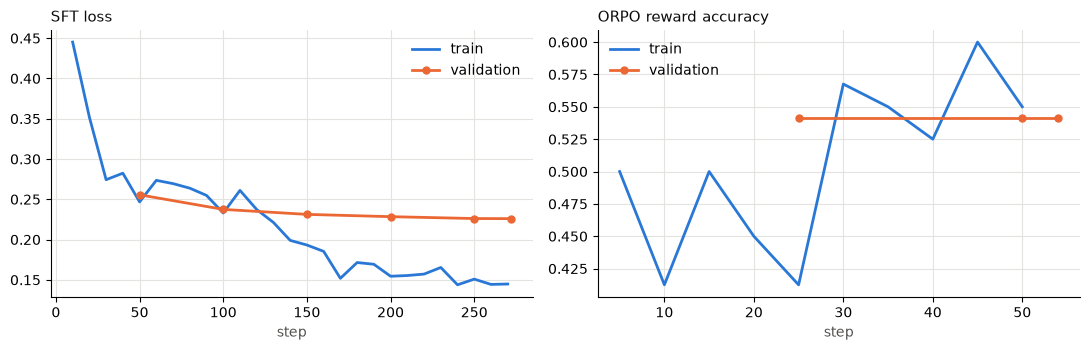

In [9]:
import matplotlib.pyplot as plt

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, stage, key, title in ((axes[0], "sft", "loss", "SFT loss"), (axes[1], "orpo", "rewards/accuracies", "ORPO reward accuracy")):
    p = Path(f"outputs/{stage}/log_history.json")
    if not p.exists():
        ax.set_visible(False)
        continue
    hist = read_json(p)
    tr = [(h["step"], h[key]) for h in hist if key in h]
    ev = [(h["step"], h["eval_" + key]) for h in hist if "eval_" + key in h]
    if tr:
        ax.plot(*zip(*tr, strict=True), color="#2a78d6", linewidth=2, label="train")
    if ev:
        ax.plot(*zip(*ev, strict=True), color="#eb6834", linewidth=2, marker="o", markersize=5, label="validation")
    ax.set_title(title, color=INK, loc="left", fontsize=11)
    ax.set_xlabel("step", color=MUTED)
    ax.grid(color=GRID, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 6. Evaluation: base vs fine-tuned

Reference-based metrics with bootstrap 95% CIs, reference-free metrics, and the independent LLM judge.
(`results/comparison_table.md` has the per-source breakdown.)

In [10]:
table = Path("results/comparison_table.md").read_text()
display(Markdown(table.split("## By data source")[0]))

# Results: base vs fine-tuned

Test set: **300 examples** from 100 held-out encounters (sources: aci-bench, mts-dialog, synthetic). Greedy decoding with identical settings for every model ({'temperature': 0.0, 'max_tokens': 1536, 'repetition_penalty': 1.05}). Values are means with bootstrap 95% CI over test examples (1000 resamples) in parentheses.

## Main comparison

| Metric | Base (Qwen2.5-7B-Instruct) | SFT | SFT + ORPO | SFT + ORPO (Q4_K_M GGUF) |
|---|---|---|---|---|
| Summary ROUGE-L ↑ | 0.383 (0.368-0.399) | **0.558 (0.535-0.580)** | 0.548 (0.522-0.573) | 0.544 (0.519-0.568) |
| Summary BERTScore F1 ↑ | 0.411 (0.392-0.430) | **0.569 (0.547-0.590)** | 0.567 (0.545-0.588) | 0.559 (0.535-0.582) |
| Summary key-entity coverage ↑ | 67.0% (61.4-72.8) | 77.2% (72.6-81.5) | 75.1% (70.5-79.7) | **79.5% (75.1-83.5)** |
| Summary length compliance ↑ | 98.0% (95.0-100.0) | **99.0% (97.0-100.0)** | **99.0% (97.0-100.0)** | 98.0% (95.0-100.0) |
| Summary medication hallucination ↓ | **0.0% (0.0-0.0)** | **0.0% (0.0-0.0)** | **0.0% (0.0-0.0)** | **0.0% (0.0-0.0)** |
| SOAP ROUGE-L ↑ | 0.583 (0.553-0.611) | 0.749 (0.718-0.776) | **0.752 (0.721-0.778)** | 0.747 (0.716-0.772) |
| SOAP BERTScore F1 ↑ | 0.471 (0.454-0.489) | 0.736 (0.701-0.765) | **0.748 (0.727-0.769)** | 0.737 (0.716-0.758) |
| SOAP structure adherence ↑ | 99.2% (97.8-100.0) | **100.0% (100.0-100.0)** | **100.0% (100.0-100.0)** | **100.0% (100.0-100.0)** |
| SOAP key-entity coverage ↑ | 94.6% (91.8-97.0) | 95.4% (92.7-97.9) | 96.3% (93.6-98.4) | **97.1% (95.1-98.9)** |
| SOAP medication hallucination ↓ | **0.0% (0.0-0.0)** | **0.0% (0.0-0.0)** | **0.0% (0.0-0.0)** | **0.0% (0.0-0.0)** |
| Entity F1 (relaxed) ↑ | 0.630 (0.600-0.659) | **0.829 (0.803-0.849)** | 0.829 (0.803-0.849) | 0.816 (0.790-0.838) |
| Entity F1 (strict) ↑ | 0.544 (0.507-0.579) | **0.798 (0.771-0.819)** | 0.796 (0.769-0.819) | 0.774 (0.744-0.800) |
| Symptom negation accuracy ↑ | 97.6% | **100.0%** | **100.0%** | 99.9% |
| Valid JSON ↑ | **100.0% (100.0-100.0)** | **100.0% (100.0-100.0)** | **100.0% (100.0-100.0)** | **100.0% (100.0-100.0)** |

## LLM-as-a-judge (judge: `Qwen/Qwen2.5-72B-Instruct`, reference-free, 1-5)

| Dimension | Base (Qwen2.5-7B-Instruct) | SFT | SFT + ORPO |
|---|---|---|---|
| faithfulness | 4.480 (4.360-4.593) | 4.720 (4.627-4.807) | 4.500 (4.370-4.637) |
| completeness | 4.307 (4.180-4.433) | 4.493 (4.360-4.620) | 4.308 (4.164-4.452) |
| format | 4.927 (4.873-4.973) | 4.933 (4.860-4.987) | 4.829 (4.733-4.918) |
| clinical_usefulness | 4.487 (4.380-4.587) | 4.607 (4.473-4.720) | 4.418 (4.274-4.569) |
| overall | 4.373 (4.267-4.473) | 4.573 (4.467-4.673) | 4.384 (4.260-4.507) |

**Pairwise (each comparison judged in both presentation orders; disagreement counts as a tie)**

| Comparison | n | win | tie | loss | position consistency |
|---|---|---|---|---|---|
| SFT + ORPO vs Base (Qwen2.5-7B-Instruct) | 150 | 20.7% | 45.3% | 34.0% | 56.0% |
| SFT + ORPO vs SFT | 150 | 4.7% | 74.0% | 21.3% | 50.0% |
| SFT vs Base (Qwen2.5-7B-Instruct) | 150 | 25.3% | 41.3% | 33.3% | 60.0% |

Pairwise by task (win / tie / loss, %):

| Comparison | summary | soap | entities |
|---|---|---|---|
| SFT + ORPO vs Base (Qwen2.5-7B-Instruct) | 22 / 54 / 24 | 12 / 48 / 40 | 28 / 34 / 38 |
| SFT + ORPO vs SFT | 8 / 74 / 18 | 2 / 76 / 22 | 4 / 72 / 24 |
| SFT vs Base (Qwen2.5-7B-Instruct) | 30 / 50 / 20 | 10 / 40 / 50 | 36 / 34 / 30 |



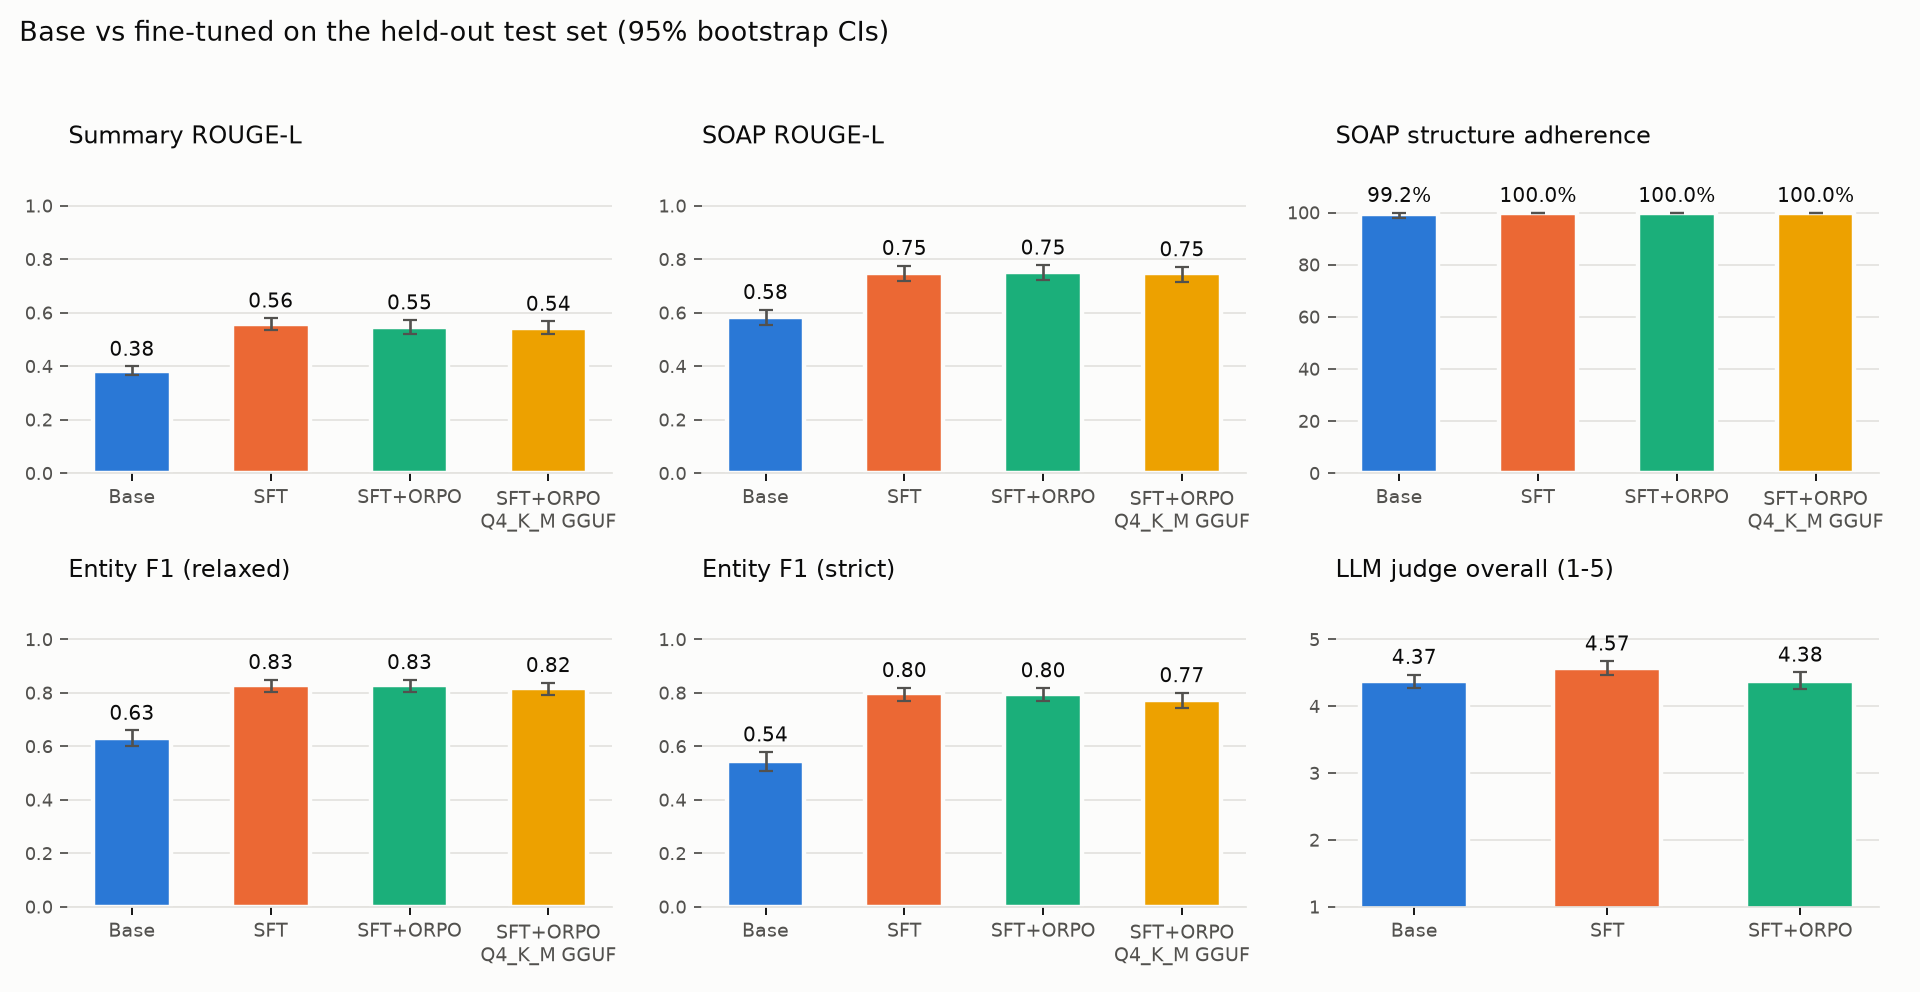

In [11]:
from IPython.display import Image

fig_path = Path("results/figures/key_metrics_light.png")
if fig_path.exists():
    display(Image(filename=str(fig_path)))

## 7. Local inference (GGUF via Ollama)

Start the demo with `bash scripts/run_demo.sh` (or `ollama serve` + `ollama create localclinical -f
serving/ollama_modelfile`). The cell below calls the OpenAI-compatible endpoint on localhost; it is skipped if the
server is not running.

In [12]:
from openai import OpenAI

note = test[3]["note"]
try:
    client = OpenAI(base_url="http://127.0.0.1:11434/v1", api_key="ollama")
    out = client.chat.completions.create(model="localclinical", messages=build_messages("summary", note),
                                         temperature=0, max_tokens=300, timeout=60)
    print(out.choices[0].message.content)
except Exception as e:
    print("Ollama is not running here - start it with `bash scripts/run_demo.sh`.", type(e).__name__)
    print("\nSample outputs from the evaluation run instead:\n")
    print(Path("results/sample_outputs.md").read_text()[:2500])

The patient is a 35-year-old female referred for acid reflux. She reports burning in her chest and throat, with symptoms worsening over the past few years despite taking omeprazole 40 mg twice daily. She denies difficulty swallowing, abdominal pain, nausea, vomiting, constipation, diarrhea, or rectal bleeding. She has a history of anxiety, seasonal allergies, and work-related stress. She had an upper endoscopy as a child but none in the last 10 years. The assessment is gastroesophageal reflux disease with underlying functional etiology. The plan includes dietary changes, addressing stress, switching to Nexium 40 mg twice daily, and scheduling an upper endoscopy.
